# Pelatihan Model CatBoost Regression
**Pemodelan Persentase Penduduk Miskin Kabupaten/Kota di Pulau Jawa Menggunakan CatBoost Regression**

Alur:
1. Setup & konfigurasi
2. Memuat data
3. Fungsi metrik evaluasi (Persamaan 2.5–2.8)
4. Validasi silang temporal & random search hiperparameter
5. Model gabungan, kabupaten, dan kota
6. Model per kabupaten/kota
7. Ringkasan evaluasi
8. Kontribusi variabel (feature importance & SHAP)
9. Grafik untuk BAB IV
10. Tabel hasil estimasi untuk dashboard
11. Menyimpan model & hasil
12. Uji muat ulang model (simulasi dashboard)

## 1. Setup & Konfigurasi

In [ ]:
!pip install -q catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.6 MB/s eta 0:00:00


In [ ]:
import os
import json
import time
import pickle
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import catboost
import sklearn
from catboost import CatBoostRegressor, Pool
from sklearn.model_selection import ParameterSampler
from scipy.stats import loguniform

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Tidak berjalan di Colab — lewati mount Google Drive.')

print('catboost', catboost.__version__, '| scikit-learn', sklearn.__version__,
      '| pandas', pd.__version__, '| python', platform.python_version())

Mounted at /content/drive
catboost 1.2.10 | scikit-learn 1.6.1 | pandas 2.2.3 | python 3.13.16


In [ ]:
BASE_DIR = '/content/drive/MyDrive/DATA_SKRIPSI'
DATA_DIR = os.path.join(BASE_DIR, 'data_processed')
MODEL_DIR = os.path.join(BASE_DIR, 'model')
HASIL_DIR = os.path.join(BASE_DIR, 'hasil')
GAMBAR_DIR = os.path.join(HASIL_DIR, 'gambar')

FITUR = ['rls', 'ahh_l', 'ahh_p', 'ppk_l', 'ppk_p', 'ikk']
TARGET = 'p0'
SEED = 42

FITUR_KATEGORIK_GABUNGAN = []

# Validasi silang temporal di dalam data latih (expanding window):
#   fold 1: latih 2014–2019 -> validasi 2020
#   fold 2: latih 2014–2020 -> validasi 2021
#   fold 3: latih 2014–2021 -> validasi 2022
TAHUN_VALIDASI_CV = [2020, 2021, 2022]

# Random search: jumlah kombinasi yang dicoba per model
N_ITER_RANDOM_SEARCH = 30

RUANG_HIPERPARAMETER = {
    'iterations':          [300, 500, 800, 1200],
    'depth':               [3, 4, 5, 6, 7, 8],
    'learning_rate':       loguniform(0.01, 0.2),
    'l2_leaf_reg':         [1, 3, 5, 7, 10],
    'random_strength':     [0.5, 1, 2, 5],
    'bagging_temperature': [0, 0.5, 1],
}

PARAM_PER_KABKOTA = dict(iterations=300, depth=2, learning_rate=0.05, l2_leaf_reg=3)

for d in (MODEL_DIR, HASIL_DIR, GAMBAR_DIR):
    os.makedirs(d, exist_ok=True)

## 2. Memuat Data

In [ ]:
dtype = {'kode_kabkota': str}
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'), dtype=dtype)
test = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'), dtype=dtype)

for nama, df in [('train', train), ('test', test)]:
    kurang = set(FITUR + [TARGET, 'kode_kabkota', 'jenis', 'tahun']) - set(df.columns)
    assert not kurang, f'{nama}.csv tidak punya kolom {kurang}'
    assert df[TARGET].notna().all(), f'{nama}.csv masih punya target kosong'

print(f'Data latih : {train.shape}  tahun {train.tahun.min()}–{train.tahun.max()}  '
      f'{train.kode_kabkota.nunique()} kab/kota')
print(f'Data uji   : {test.shape}  tahun {test.tahun.min()}–{test.tahun.max()}  '
      f'{test.kode_kabkota.nunique()} kab/kota')
print('\nNilai kosong pada fitur (ditangani CatBoost secara bawaan):')
print(pd.DataFrame({'latih': train[FITUR].isna().sum(), 'uji': test[FITUR].isna().sum()}).T)

Data latih : (1070, 12)  tahun 2014–2022  119 kab/kota
Data uji   : (238, 12)  tahun 2023–2024  119 kab/kota

Nilai kosong pada fitur (ditangani CatBoost secara bawaan):
       rls  ahh_l  ahh_p  ppk_l  ppk_p  ikk
latih    0      0      0      0      0   12
uji      0      0      0      0      0    0


## 3. Fungsi Metrik Evaluasi


In [ ]:
def rmse(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return float(np.sqrt(np.mean((y - yhat) ** 2)))                    # Persamaan (2.5)

def mae(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return float(np.mean(np.abs(y - yhat)))                            # Persamaan (2.6)

def mape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return float(100 * np.mean(np.abs((y - yhat) / y)))               # Persamaan (2.7)

def r2(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    ss_tot = np.sum((y - y.mean()) ** 2)
    if ss_tot == 0:
        return np.nan
    return float(1 - np.sum((y - yhat) ** 2) / ss_tot)                # Persamaan (2.8)

def semua_metrik(y, yhat):
    return {'RMSE': rmse(y, yhat), 'MAE': mae(y, yhat), 'MAPE (%)': mape(y, yhat),
            'R2': r2(y, yhat), 'n': len(y)}

_y, _yhat = [12.5, 8.0, 15.2, 5.5, 10.0], [11.8, 8.6, 14.0, 6.1, 9.7]
print({k: round(v, 3) for k, v in semua_metrik(_y, _yhat).items()})

{'RMSE': 0.74, 'MAE': 0.68, 'MAPE (%)': 6.981, 'R2': 0.952, 'n': 5}


## 4. Cross Validation Temporal & Random Search

In [ ]:
def kolom_fitur(kategorik=()):
    return list(FITUR) + list(kategorik)


def buat_pool(df, kategorik=(), dengan_target=True):
    kolom = kolom_fitur(kategorik)
    return Pool(df[kolom], label=df[TARGET] if dengan_target else None,
                cat_features=list(kategorik) or None)


def buat_model(params):
    return CatBoostRegressor(loss_function='RMSE', random_seed=SEED, verbose=False,
                             allow_writing_files=False, thread_count=-1, **params)


def skor_cv_temporal(df, params, kategorik=()):
    skor = []
    for th in TAHUN_VALIDASI_CV:
        latih, val = df[df.tahun < th], df[df.tahun == th]
        if latih.empty or val.empty:
            continue
        m = buat_model(params)
        m.fit(buat_pool(latih, kategorik))
        skor.append(rmse(val[TARGET], m.predict(buat_pool(val, kategorik, False))))
    return float(np.mean(skor)), skor


def random_search(df, nama, kategorik=()):
    kandidat = list(ParameterSampler(RUANG_HIPERPARAMETER, n_iter=N_ITER_RANDOM_SEARCH,
                                     random_state=SEED))
    hasil = []
    t0 = time.time()
    for i, p in enumerate(kandidat, 1):
        p = {k: (round(float(v), 5) if k == 'learning_rate' else v) for k, v in p.items()}
        rata, per_fold = skor_cv_temporal(df, p, kategorik)
        hasil.append({**p, 'rmse_cv': rata, **{f'rmse_{th}': s for th, s in zip(TAHUN_VALIDASI_CV, per_fold)}})
        if i % 5 == 0 or i == len(kandidat):
            terbaik = min(h['rmse_cv'] for h in hasil)
            print(f'  [{nama}] {i}/{len(kandidat)} kombinasi | RMSE-CV terbaik {terbaik:.4f} '
                  f'| {time.time() - t0:.0f} dtk')
    hasil = pd.DataFrame(hasil).sort_values('rmse_cv').reset_index(drop=True)
    terbaik = {k: hasil.loc[0, k] for k in RUANG_HIPERPARAMETER}
    terbaik = {k: (int(v) if isinstance(v, (np.integer,)) or k in ('iterations', 'depth') else float(v))
               for k, v in terbaik.items()}
    return terbaik, hasil

## 5. Model Gabungan, Kabupaten, dan Kota

In [ ]:
KELOMPOK = {
    'gabungan':  dict(filter=None,        kategorik=FITUR_KATEGORIK_GABUNGAN),
    'kabupaten': dict(filter='Kabupaten', kategorik=[]),
    'kota':      dict(filter='Kota',      kategorik=[]),
}

model_utama, param_terbaik, hasil_search, prediksi_uji = {}, {}, {}, {}

for nama, cfg in KELOMPOK.items():
    print(f'\n=== MODEL {nama.upper()} ===')
    tr = train if cfg['filter'] is None else train[train.jenis == cfg['filter']]
    te = test if cfg['filter'] is None else test[test.jenis == cfg['filter']]
    print(f'  data latih {len(tr)} baris, data uji {len(te)} baris')

    best, tabel = random_search(tr, nama, cfg['kategorik'])
    print(f'  hiperparameter terbaik: {best}')

    model = buat_model(best)
    model.fit(buat_pool(tr, cfg['kategorik']))
    yhat = model.predict(buat_pool(te, cfg['kategorik'], False))

    model_utama[nama] = model
    param_terbaik[nama] = best
    hasil_search[nama] = tabel
    prediksi_uji[nama] = pd.DataFrame({'kode_kabkota': te.kode_kabkota.values,
                                       'jenis': te.jenis.values, 'tahun': te.tahun.values,
                                       'aktual': te[TARGET].values, 'prediksi': yhat})
    m = semua_metrik(te[TARGET], yhat)
    print('  evaluasi data uji:', {k: round(v, 4) if isinstance(v, float) else v for k, v in m.items()})


=== MODEL GABUNGAN ===
  data latih 1070 baris, data uji 238 baris
  [gabungan] 5/30 kombinasi | RMSE-CV terbaik 1.8643 | 17 dtk
  [gabungan] 10/30 kombinasi | RMSE-CV terbaik 1.8365 | 37 dtk
  [gabungan] 15/30 kombinasi | RMSE-CV terbaik 1.8365 | 71 dtk
  [gabungan] 20/30 kombinasi | RMSE-CV terbaik 1.8365 | 79 dtk
  [gabungan] 25/30 kombinasi | RMSE-CV terbaik 1.7478 | 106 dtk
  [gabungan] 30/30 kombinasi | RMSE-CV terbaik 1.7478 | 135 dtk
  hiperparameter terbaik: {'iterations': 1200, 'depth': 8, 'learning_rate': 0.08897, 'l2_leaf_reg': 10, 'random_strength': 5.0, 'bagging_temperature': 0.0}
  evaluasi data uji: {'RMSE': 2.2921, 'MAE': 1.7513, 'MAPE (%)': 20.1289, 'R2': 0.6259, 'n': 238}

=== MODEL KABUPATEN ===
  data latih 764 baris, data uji 170 baris
  [kabupaten] 5/30 kombinasi | RMSE-CV terbaik 1.8984 | 18 dtk
  [kabupaten] 10/30 kombinasi | RMSE-CV terbaik 1.8984 | 38 dtk
  [kabupaten] 15/30 kombinasi | RMSE-CV terbaik 1.8984 | 71 dtk
  [kabupaten] 20/30 kombinasi | RMSE-CV 

In [ ]:
hasil_search['gabungan'].head(5).round(4)

,bagging_temperature,depth,iterations,l2_leaf_reg,learning_rate,random_strength,rmse_cv,rmse_2020,rmse_2021,rmse_2022
0,0.0,8,1200,10,0.0890,5.0,1.7478,1.8115,1.6563,1.7755
1,0.5,8,800,5,0.0314,5.0,1.8365,1.9022,1.8097,1.7977
2,0.5,8,500,3,0.0548,0.5,1.8642,1.9545,1.7804,1.8578
3,1.0,8,300,3,0.0870,1.0,1.8643,1.9407,1.8079,1.8443
4,1.0,5,800,7,0.1620,0.5,1.9129,2.0744,1.8798,1.7844


## 6. Model per Kabupaten/Kota

In [ ]:
model_per_kabkota, baris_metrik, baris_pred = {}, [], []
t0 = time.time()
for kode, tr in train.groupby('kode_kabkota'):
    te = test[test.kode_kabkota == kode]
    model = buat_model(PARAM_PER_KABKOTA)
    model.fit(buat_pool(tr))
    model_per_kabkota[kode] = model
    if te.empty:
        continue
    yhat = model.predict(buat_pool(te, dengan_target=False))
    y = te[TARGET].values
    baris_pred.append(pd.DataFrame({'kode_kabkota': kode, 'jenis': te.jenis.values,
                                    'tahun': te.tahun.values, 'aktual': y, 'prediksi': yhat}))
    lo, hi = tr[TARGET].min(), tr[TARGET].max()
    baris_metrik.append({
        'kode_kabkota': kode, 'nama_kabkota': tr.nama_kabkota.iloc[0], 'jenis': tr.jenis.iloc[0],
        'n_latih': len(tr), 'n_uji': len(te),
        'RMSE': rmse(y, yhat), 'MAE': mae(y, yhat), 'MAPE (%)': mape(y, yhat),
        'p0_latih_min': lo, 'p0_latih_max': hi,
        'di_luar_rentang_latih': bool(((y < lo) | (y > hi)).any()),
    })
print(f'{len(model_per_kabkota)} model per kab/kota dilatih dalam {time.time() - t0:.0f} dtk')

prediksi_uji['per_kabkota'] = pd.concat(baris_pred, ignore_index=True)
metrik_kabkota = pd.DataFrame(baris_metrik).sort_values('RMSE').reset_index(drop=True)

n_luar = metrik_kabkota['di_luar_rentang_latih'].sum()
print(f'Wilayah dengan nilai aktual uji di luar rentang target data latihnya: '
      f'{n_luar} dari {len(metrik_kabkota)}')
print('\n5 wilayah dengan RMSE terkecil:')
print(metrik_kabkota.head(5)[['nama_kabkota', 'RMSE', 'MAE', 'MAPE (%)']].round(3).to_string(index=False))
print('\n5 wilayah dengan RMSE terbesar:')
print(metrik_kabkota.tail(5)[['nama_kabkota', 'RMSE', 'MAE', 'MAPE (%)', 'di_luar_rentang_latih']]
      .round(3).to_string(index=False))

119 model per kab/kota dilatih dalam 4 dtk
Wilayah dengan nilai aktual uji di luar rentang target data latihnya: 62 dari 119

5 wilayah dengan RMSE terkecil:
          nama_kabkota  RMSE   MAE  MAPE (%)
            Kab. Blora 0.029 0.028     0.244
          Kab. Cianjur 0.037 0.034     0.334
    Kota Jakarta Timur 0.067 0.055     1.340
Kota Tangerang Selatan 0.107 0.106     4.341
        Kab. Sukoharjo 0.124 0.106     1.411

5 wilayah dengan RMSE terbesar:
    nama_kabkota  RMSE   MAE  MAPE (%)  di_luar_rentang_latih
   Kab. Wonosobo 1.024 1.022     6.622                   True
   Kota Magelang 1.099 1.096    18.214                   True
Kota Tasikmalaya 1.397 1.380    12.237                   True
  Kab. Bondowoso 1.687 1.644    12.771                   True
    Kab. Sampang 2.136 2.085     9.841                  False


## 7. Ringkasan Evaluasi pada Data Uji 2023–2024


In [ ]:
def ringkas(nama, df):
    return {'model': nama, **semua_metrik(df['aktual'], df['prediksi'])}

pg = prediksi_uji['gabungan']
ringkasan = pd.DataFrame([
    ringkas('Gabungan (119 kab/kota)', pg),
    ringkas('Gabungan — subset kabupaten', pg[pg.jenis == 'Kabupaten']),
    ringkas('Kabupaten (85)', prediksi_uji['kabupaten']),
    ringkas('Gabungan — subset kota', pg[pg.jenis == 'Kota']),
    ringkas('Kota (34)', prediksi_uji['kota']),
    ringkas('Per kab/kota (119 model, gabungan semua prediksi)', prediksi_uji['per_kabkota']),
])
ringkasan.round(4)

,model,RMSE,MAE,MAPE (%),R2,n
0,Gabungan (119 kab/kota),2.2921,1.7513,20.1289,0.6259,238
1,Gabungan — subset kabupaten,2.5425,2.0108,19.5677,0.3849,170
2,Kabupaten (85),2.4838,1.9314,19.9744,0.4129,170
3,Gabungan — subset kota,1.4925,1.1024,21.5317,0.3959,68
4,Kota (34),1.1501,0.8637,15.8209,0.6413,68
5,"Per kab/kota (119 model, gabungan semua prediksi)",0.5739,0.4432,5.3170,0.9765,238


In [ ]:
print('Sebaran metrik model per kab/kota (119 wilayah):')
metrik_kabkota[['RMSE', 'MAE', 'MAPE (%)']].describe().round(3)

Sebaran metrik model per kab/kota (119 wilayah):


,RMSE,MAE,MAPE (%)
count,119.000,119.000,119.000
mean,0.477,0.443,5.317
std,0.321,0.313,3.691
min,0.029,0.028,0.244
25%,0.238,0.215,2.546
50%,0.409,0.380,4.669
75%,0.641,0.590,6.694
max,2.136,2.085,22.957


## 8. Kontribusi Variabel


In [ ]:
LABEL_FITUR = {
    'rls': 'Rata-rata Lama Sekolah', 'ahh_l': 'AHH Laki-laki', 'ahh_p': 'AHH Perempuan',
    'ppk_l': 'Pengeluaran per Kapita Laki-laki', 'ppk_p': 'Pengeluaran per Kapita Perempuan',
    'ikk': 'Indeks Kemahalan Konstruksi', 'jenis': 'Jenis Wilayah',
}

def kontribusi(model, df_uji, kategorik=()):
    kolom = kolom_fitur(kategorik)
    fi = model.get_feature_importance(type='PredictionValuesChange')
    shap = model.get_feature_importance(buat_pool(df_uji, kategorik, False), type='ShapValues')
    return pd.DataFrame({'variabel': kolom, 'feature_importance': fi,
                         'mean_abs_shap': np.abs(shap[:, :-1]).mean(axis=0)})

baris_kontrib = []
for nama, cfg in KELOMPOK.items():
    te = test if cfg['filter'] is None else test[test.jenis == cfg['filter']]
    k = kontribusi(model_utama[nama], te, cfg['kategorik'])
    k.insert(0, 'model', nama)
    baris_kontrib.append(k)

# model per kab/kota: rata-rata kontribusi dari 119 model
fi_wil = []
for kode, m in model_per_kabkota.items():
    te = test[test.kode_kabkota == kode]
    if len(te):
        fi_wil.append(kontribusi(m, te))
fi_wil = pd.concat(fi_wil).groupby('variabel', sort=False)[['feature_importance', 'mean_abs_shap']].mean().reset_index()
fi_wil.insert(0, 'model', 'per_kabkota (rata-rata 119 model)')
baris_kontrib.append(fi_wil)

tabel_kontribusi = pd.concat(baris_kontrib, ignore_index=True)
tabel_kontribusi['label'] = tabel_kontribusi['variabel'].map(LABEL_FITUR)
(tabel_kontribusi.pivot(index='label', columns='model', values='feature_importance')
 .sort_values('gabungan', ascending=False).round(2))

model,gabungan,kabupaten,kota,per_kabkota (rata-rata 119 model)
label,,,,
Rata-rata Lama Sekolah,34.63,30.85,13.26,14.94
Pengeluaran per Kapita Perempuan,18.42,17.89,24.81,15.02
Pengeluaran per Kapita Laki-laki,14.54,13.25,38.75,14.50
AHH Perempuan,11.45,12.77,8.68,15.34
AHH Laki-laki,10.75,13.24,8.49,24.40
Indeks Kemahalan Konstruksi,10.22,12.00,6.01,15.80


## 9. Grafik

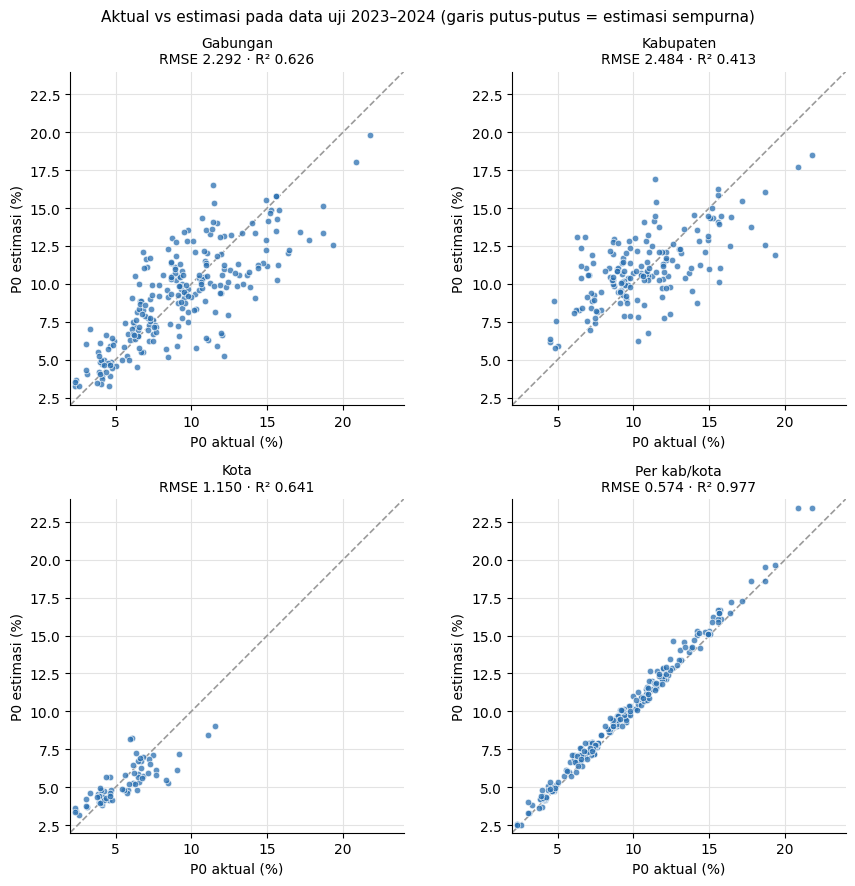

In [ ]:
WARNA = '#2a6fb0'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e3e3e3', 'grid.linewidth': 0.8,
                     'axes.axisbelow': True})

panel_plot = [('Gabungan', prediksi_uji['gabungan']), ('Kabupaten', prediksi_uji['kabupaten']),
              ('Kota', prediksi_uji['kota']), ('Per kab/kota', prediksi_uji['per_kabkota'])]
semua = pd.concat([d for _, d in panel_plot])
lo, hi = np.floor(semua[['aktual', 'prediksi']].min().min()), np.ceil(semua[['aktual', 'prediksi']].max().max())

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, (judul, d) in zip(axes.flat, panel_plot):
    ax.plot([lo, hi], [lo, hi], color='#9a9a9a', lw=1.2, ls='--', zorder=1)
    ax.scatter(d['aktual'], d['prediksi'], s=22, color=WARNA, alpha=0.75,
               edgecolor='white', linewidth=0.6, zorder=2)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_title(f'{judul}\nRMSE {rmse(d.aktual, d.prediksi):.3f} · R² {r2(d.aktual, d.prediksi):.3f}',
                 fontsize=10)
    ax.set_xlabel('P0 aktual (%)'); ax.set_ylabel('P0 estimasi (%)')
fig.suptitle('Aktual vs estimasi pada data uji 2023–2024 (garis putus-putus = estimasi sempurna)', fontsize=11)
fig.tight_layout()
fig.savefig(os.path.join(GAMBAR_DIR, 'aktual_vs_estimasi.png'), dpi=200, bbox_inches='tight')
plt.show()

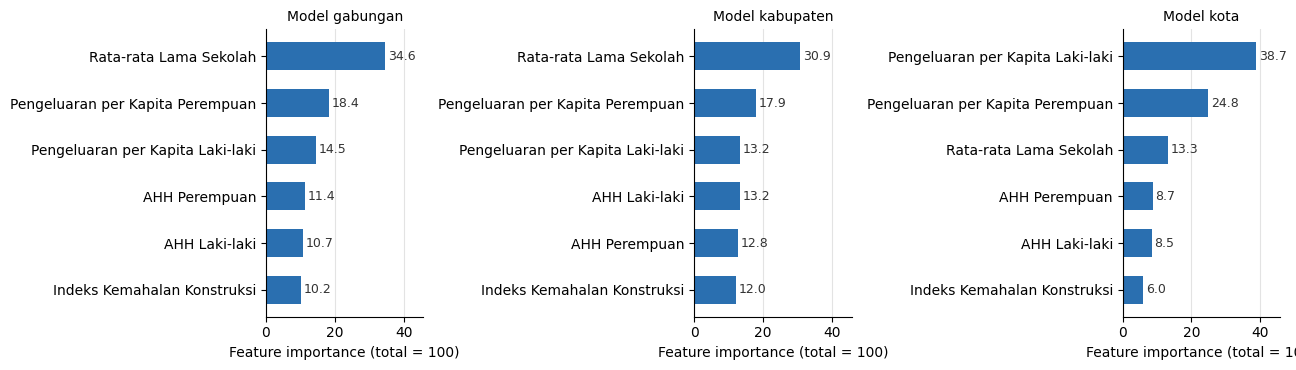

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
for ax, nama in zip(axes, ['gabungan', 'kabupaten', 'kota']):
    d = tabel_kontribusi[tabel_kontribusi.model == nama].sort_values('feature_importance')
    ax.barh(d['label'], d['feature_importance'], color=WARNA, height=0.6)
    for y, v in enumerate(d['feature_importance']):
        ax.text(v + 0.8, y, f'{v:.1f}', va='center', fontsize=9, color='#333333')
    ax.set_title(f'Model {nama}', fontsize=10)
    ax.set_xlabel('Feature importance (total = 100)')
    ax.grid(axis='y', visible=False)
axes[0].set_xlim(0, tabel_kontribusi['feature_importance'].max() * 1.18)
fig.tight_layout()
fig.savefig(os.path.join(GAMBAR_DIR, 'feature_importance.png'), dpi=200, bbox_inches='tight')
plt.show()

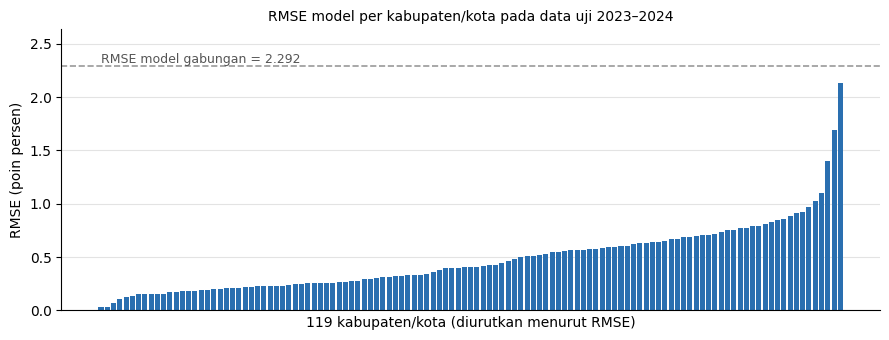

In [ ]:
# RMSE per kab/kota (model per wilayah)
d = metrik_kabkota.sort_values('RMSE')
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(d)), d['RMSE'], color=WARNA, width=0.8)
rmse_gab = rmse(prediksi_uji['gabungan'].aktual, prediksi_uji['gabungan'].prediksi)
ax.axhline(rmse_gab, color='#9a9a9a', ls='--', lw=1.2)
ax.set_ylim(0, max(d['RMSE'].max(), rmse_gab) * 1.15)
ax.text(0, rmse_gab, f'RMSE model gabungan = {rmse_gab:.3f}', fontsize=9, color='#555555',
        va='bottom', ha='left')
ax.set_xticks([]); ax.set_xlabel('119 kabupaten/kota (diurutkan menurut RMSE)')
ax.set_ylabel('RMSE (poin persen)')
ax.set_title('RMSE model per kabupaten/kota pada data uji 2023–2024', fontsize=10)
ax.grid(axis='x', visible=False)
fig.tight_layout()
fig.savefig(os.path.join(GAMBAR_DIR, 'rmse_per_kabkota.png'), dpi=200, bbox_inches='tight')
plt.show()

## 10. Tabel Hasil Estimasi untuk Dashboard

In [ ]:
panel = pd.concat([train.assign(data='latih'), test.assign(data='uji')], ignore_index=True)
panel = panel.sort_values(['kode_kabkota', 'tahun']).reset_index(drop=True)

kat = KELOMPOK['gabungan']['kategorik']
panel['estimasi_gabungan'] = model_utama['gabungan'].predict(buat_pool(panel, kat, False))

panel['estimasi_jenis'] = np.nan
for nama, j in [('kabupaten', 'Kabupaten'), ('kota', 'Kota')]:
    m = panel.jenis == j
    panel.loc[m, 'estimasi_jenis'] = model_utama[nama].predict(buat_pool(panel[m], dengan_target=False))

panel['estimasi_kabkota'] = np.nan
for kode, idx in panel.groupby('kode_kabkota').groups.items():
    if kode in model_per_kabkota:
        panel.loc[idx, 'estimasi_kabkota'] = model_per_kabkota[kode].predict(
            buat_pool(panel.loc[idx], dengan_target=False))

# kontribusi SHAP model gabungan per baris
shap = model_utama['gabungan'].get_feature_importance(buat_pool(panel, kat, False), type='ShapValues')
for i, f in enumerate(kolom_fitur(kat)):
    panel[f'shap_{f}'] = shap[:, i]
panel['shap_nilai_dasar'] = shap[:, -1]

hasil_estimasi = panel.rename(columns={TARGET: 'p0_aktual'})
kolom_urut = (['kode_kabkota', 'nama_kabkota', 'provinsi', 'jenis', 'tahun', 'data'] + FITUR
              + ['p0_aktual', 'estimasi_gabungan', 'estimasi_jenis', 'estimasi_kabkota']
              + [c for c in hasil_estimasi.columns if c.startswith('shap_')])
hasil_estimasi = hasil_estimasi[kolom_urut]

# pemeriksaan: nilai dasar + jumlah SHAP = estimasi model gabungan
selisih = (hasil_estimasi.filter(like='shap_').sum(axis=1) - hasil_estimasi['estimasi_gabungan']).abs().max()
print(f'Selisih maksimum (nilai dasar + ΣSHAP) vs estimasi: {selisih:.2e}')
print(hasil_estimasi.shape)
hasil_estimasi.head()

Selisih maksimum (nilai dasar + ΣSHAP) vs estimasi: 4.26e-14
(1308, 23)


,kode_kabkota,nama_kabkota,provinsi,jenis,tahun,data,rls,ahh_l,ahh_p,ppk_l,ppk_p,ikk,p0_aktual,estimasi_gabungan,estimasi_jenis,estimasi_kabkota,shap_rls,shap_ahh_l,shap_ahh_p,shap_ppk_l,shap_ppk_p,shap_ikk,shap_nilai_dasar
0,3101,Kab. Kepulauan Seribu,DKI Jakarta,Kabupaten,2014,latih,8.03,65.510,68.830,16054.10,10887.55,NaN,11.56,11.185223,11.517154,11.534738,-0.684297,-0.582608,0.050302,0.348292,0.541974,1.210895,10.300665
1,3101,Kab. Kepulauan Seribu,DKI Jakarta,Kabupaten,2015,latih,8.04,66.010,69.330,16107.58,11077.58,NaN,11.40,11.355662,11.462984,11.456120,-0.624526,-0.511467,0.063181,0.394964,0.534766,1.198079,10.300665
2,3101,Kab. Kepulauan Seribu,DKI Jakarta,Kabupaten,2016,latih,8.24,66.055,69.645,16393.79,11241.79,133.29,12.58,12.660036,12.660288,12.587088,-0.680964,-0.184580,0.411206,0.105862,0.473306,2.234541,10.300665
3,3101,Kab. Kepulauan Seribu,DKI Jakarta,Kabupaten,2017,latih,8.25,66.100,69.960,16680.00,11406.00,127.10,12.98,13.099326,12.757382,12.959925,-0.601078,-0.169569,0.419977,0.182593,0.487900,2.478839,10.300665
4,3101,Kab. Kepulauan Seribu,DKI Jakarta,Kabupaten,2018,latih,8.46,66.300,70.220,17196.00,11765.00,116.74,11.98,11.644546,11.830618,11.955079,-0.767503,-0.141500,0.539346,0.087981,0.304308,1.321249,10.300665


## 11. Menyimpan Model & Hasil

In [ ]:
def simpan_pickle(obj, nama_file):
    path = os.path.join(MODEL_DIR, nama_file)
    with open(path, 'wb') as f:
        pickle.dump(obj, f)
    return path

for nama, m in model_utama.items():
    simpan_pickle(m, f'model_{nama}.pkl')
simpan_pickle(model_per_kabkota, 'model_per_kabkota.pkl')

with open(os.path.join(DATA_DIR, 'rentang_fitur.json')) as f:
    rentang = json.load(f)['rentang']

metadata = {
    'fitur': FITUR,
    'fitur_kategorik_gabungan': list(FITUR_KATEGORIK_GABUNGAN),
    'target': TARGET,
    'label_fitur': {k: v for k, v in LABEL_FITUR.items() if k in kolom_fitur(FITUR_KATEGORIK_GABUNGAN)},
    'tahun_latih': [int(train.tahun.min()), int(train.tahun.max())],
    'tahun_uji': sorted(int(t) for t in test.tahun.unique()),
    'hiperparameter': {**param_terbaik, 'per_kabkota': PARAM_PER_KABKOTA},
    'rentang_fitur_latih': rentang,
    'versi': {'catboost': catboost.__version__, 'scikit-learn': sklearn.__version__,
              'pandas': pd.__version__, 'numpy': np.__version__, 'python': platform.python_version()},
}
with open(os.path.join(MODEL_DIR, 'metadata.json'), 'w') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

ringkasan.to_csv(os.path.join(HASIL_DIR, 'metrik_evaluasi.csv'), index=False)
metrik_kabkota.to_csv(os.path.join(HASIL_DIR, 'metrik_per_kabkota.csv'), index=False)
tabel_kontribusi.to_csv(os.path.join(HASIL_DIR, 'kontribusi_variabel.csv'), index=False)
for nama, tabel in hasil_search.items():
    tabel.to_csv(os.path.join(HASIL_DIR, f'random_search_{nama}.csv'), index=False)
pd.concat([d.assign(model=n) for n, d in prediksi_uji.items()]).to_csv(
    os.path.join(HASIL_DIR, 'prediksi_data_uji.csv'), index=False)
hasil_estimasi.to_csv(os.path.join(HASIL_DIR, 'hasil_estimasi.csv'), index=False)

for folder in (MODEL_DIR, HASIL_DIR, GAMBAR_DIR):
    print(folder)
    for f in sorted(os.listdir(folder)):
        p = os.path.join(folder, f)
        if os.path.isfile(p):
            print(f'  {f:34s} {os.path.getsize(p) / 1024:9.1f} KB')

/content/drive/MyDrive/DATA_SKRIPSI/model
  metadata.json                            2.3 KB
  model_gabungan.pkl                    4916.2 KB
  model_kabupaten.pkl                   4913.2 KB
  model_kota.pkl                        2034.1 KB
  model_per_kabkota.pkl                 4852.1 KB
/content/drive/MyDrive/DATA_SKRIPSI/hasil
  hasil_estimasi.csv                     367.7 KB
  kontribusi_variabel.csv                  2.0 KB
  metrik_evaluasi.csv                      0.6 KB
  metrik_per_kabkota.csv                  12.3 KB
  prediksi_data_uji.csv                   36.3 KB
  random_search_gabungan.csv               3.0 KB
  random_search_kabupaten.csv              3.0 KB
  random_search_kota.csv                   3.0 KB
/content/drive/MyDrive/DATA_SKRIPSI/hasil/gambar
  aktual_vs_estimasi.png                 264.8 KB
  feature_importance.png                 104.5 KB
  rmse_per_kabkota.png                    54.8 KB


## 12. Uji Load Ulang Model (Simulasi Dashboard)


In [ ]:
with open(os.path.join(MODEL_DIR, 'model_gabungan.pkl'), 'rb') as f:
    model_dimuat = pickle.load(f)
with open(os.path.join(MODEL_DIR, 'metadata.json')) as f:
    meta = json.load(f)

def estimasi(model, nilai, meta):
    """nilai: dict {nama_fitur: angka}. Mengembalikan (estimasi, kontribusi, peringatan)."""
    kolom = meta['fitur'] + meta['fitur_kategorik_gabungan']
    peringatan = []
    for f in meta['fitur']:
        r = meta['rentang_fitur_latih'][f]
        if not (r['min'] <= nilai[f] <= r['max']):
            peringatan.append(f"{r['label']} = {nilai[f]} di luar rentang data latih "
                              f"[{r['min']:.2f}, {r['max']:.2f}]")
    df = pd.DataFrame([nilai])[kolom]
    pool = Pool(df, cat_features=meta['fitur_kategorik_gabungan'] or None)
    yhat = float(model.predict(pool)[0])
    shap = model.get_feature_importance(pool, type='ShapValues')[0]
    kontrib = pd.Series(shap[:-1], index=[meta['label_fitur'][k] for k in kolom]).sort_values(key=abs, ascending=False)
    return yhat, kontrib, shap[-1], peringatan

contoh = test.iloc[0]
nilai = {f: float(contoh[f]) for f in FITUR}
nilai.update({f: contoh[f] for f in FITUR_KATEGORIK_GABUNGAN})
yhat, kontrib, dasar, peringatan = estimasi(model_dimuat, nilai, meta)

print(f'Wilayah contoh : {contoh.nama_kabkota} {contoh.tahun}')
print(f'P0 aktual      : {contoh[TARGET]:.2f}%')
print(f'P0 estimasi    : {yhat:.2f}%  (nilai dasar {dasar:.2f} + jumlah kontribusi {kontrib.sum():+.2f})')
print('Kontribusi variabel (poin persen):')
print(kontrib.round(3).to_string())
print('Peringatan:', peringatan or 'tidak ada')
assert abs(yhat - model_utama['gabungan'].predict(buat_pool(test.iloc[[0]], kat, False))[0]) < 1e-9

Wilayah contoh : Kab. Kepulauan Seribu 2023
P0 aktual      : 13.13%
P0 estimasi    : 10.58%  (nilai dasar 10.30 + jumlah kontribusi +0.28)
Kontribusi variabel (poin persen):
Indeks Kemahalan Konstruksi         1.172
Rata-rata Lama Sekolah             -0.676
Pengeluaran per Kapita Laki-laki   -0.520
AHH Perempuan                       0.289
Pengeluaran per Kapita Perempuan    0.072
AHH Laki-laki                      -0.055
Peringatan: tidak ada
